# Spectrogram & Formant Analysis — Speech DSP

Classical speech-signal analysis on instrument and human-voice recordings:

- Waveform + STFT spectrograms (wideband vs narrowband `n_fft`)
- F0 / pitch tracking via `librosa.pyin`
- Formant structure: why flute & violin lack the clear formants of human vowels
- Gender-based comparison of male vs female vowel spectrograms

Audio assets live in `audio/dataset/`. Run top-to-bottom.

# Part 1

## 1 Loading Audio file and creating a widget

In [38]:
import librosa as lb

In [39]:
flute_time, flute_sampling =lb.load("audio/dataset/flute.wav")

In [40]:
from IPython.display import Audio
Audio(flute_time, rate=flute_sampling)

## 2 Plotting the wave form

In [41]:
import matplotlib.pyplot as plt
import numpy as np

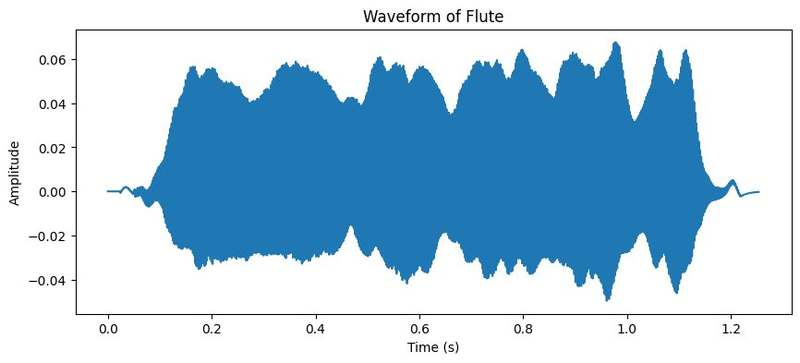

In [42]:
plt.figure(figsize=(10, 4))
plt.plot(np.linspace(0, len(flute_time) / flute_sampling, len(flute_time)), flute_time) #Similar to matlab
plt.title("Waveform of Flute")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()
Audio(flute_time, rate=flute_sampling)

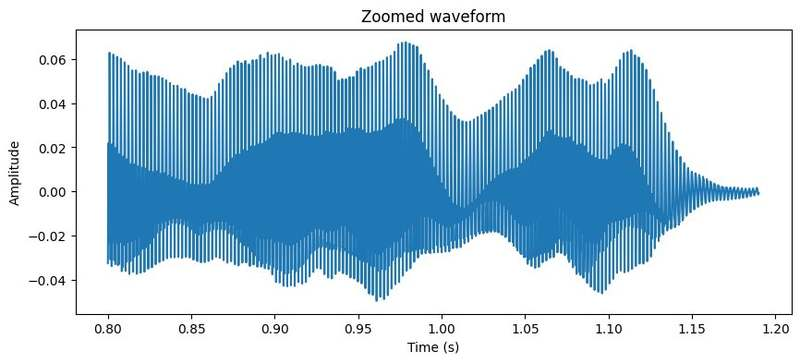

In [43]:
start_time = 0.8
end_time = 1.19

start_sample = int(start_time * flute_sampling)
end_sample = int(end_time * flute_sampling)

y_segment = flute_time[start_sample:end_sample]
time_segment = np.linspace(start_time, end_time, len(y_segment))

# Plot the waveform for the selected segment
plt.figure(figsize=(10, 4))
plt.plot(time_segment, y_segment)
plt.title("Zoomed waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()


## 3 Performing STFT and plotting the spectrogram

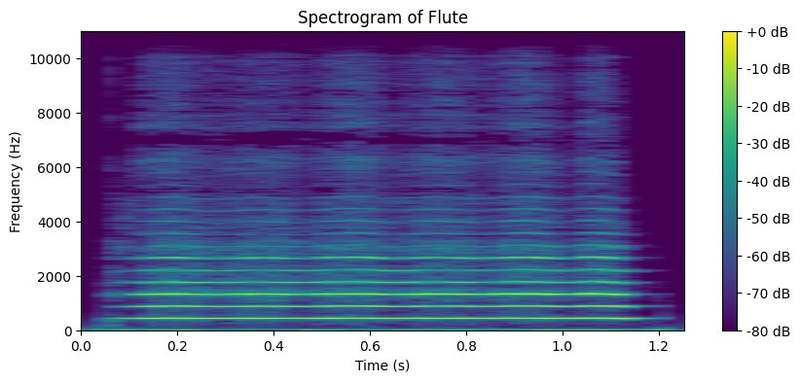

In [44]:
D_flute = lb.stft(flute_time)
S_db_flute = lb.amplitude_to_db(np.abs(D_flute), ref=np.max)

plt.figure(figsize=(10, 4))
plt.imshow(S_db_flute, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(flute_time) / flute_sampling, 0, flute_sampling / 2])
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram of Flute")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()

### Unlike human sounds, flute sound doesn't display a specific formant. Instead, it displays strong and continous harmonic content in its lower spectrogram region, and a weak but still continuous harmonic content in the higher region.
### These differences allow us to differentiate between a human sound and background music in case of speech analysis.

# Part 2

## 1 Computing and Plotting Spectrograms

In [45]:
vi1_time, vi1_sampling =lb.load("audio/dataset/violin1.wav")
vi2_time, vi2_sampling =lb.load("audio/dataset/violin2.wav")


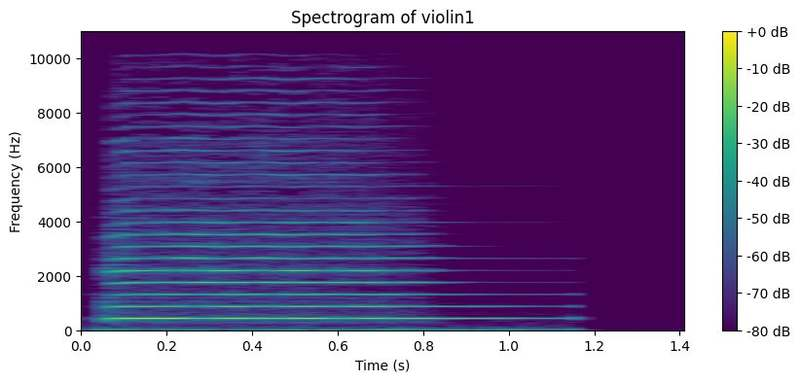

In [46]:
vi1_D = lb.stft(vi1_time)
S_db_vi1 = lb.amplitude_to_db(np.abs(vi1_D), ref=np.max)

plt.figure(figsize=(10, 4))
plt.imshow(S_db_vi1, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(vi1_time) / vi1_sampling, 0, vi1_sampling / 2])
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram of violin1")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()
Audio(vi1_time, rate=vi1_sampling)

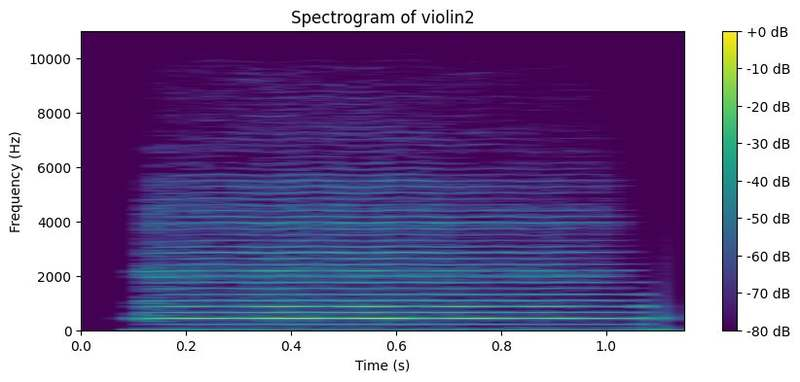

In [47]:
vi2_D = lb.stft(vi2_time)
S_db_vi2 = lb.amplitude_to_db(np.abs(vi2_D), ref=np.max)

plt.figure(figsize=(10, 4))
plt.imshow(S_db_vi2, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(vi2_time) / vi2_sampling, 0, vi2_sampling / 2])
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram of violin2")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()
Audio(vi2_time, rate=vi2_sampling)

### Violin spectrograms also lack specific formants like the flute. However, the harmonic structure of the violin are clearly more complex than those of the flute and their intensity is also more distrubuted of the upper and lower regions of the spectrograms.
### Violin1 seems to have a higher intensity while Violin2's harmonic structure appears to be more complex. Also, violin1's higher frequencies appear to stop a while before the lower ones while the frequencies of violin2 end roughly at the same time even if their lower intensities make it harder to spot in the spectrogram.

## 2 Plotting F0 values in a graph

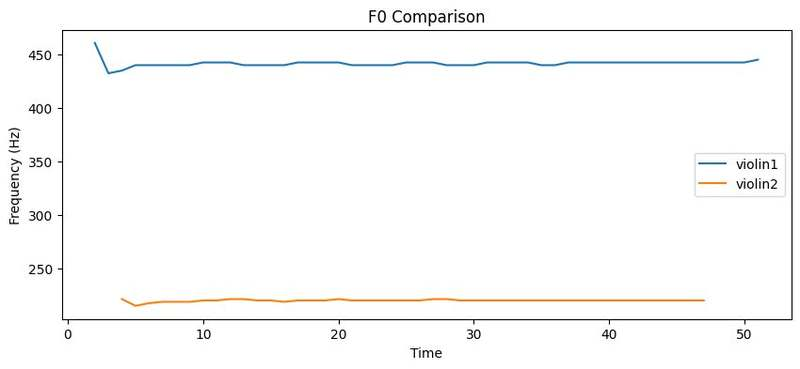

In [48]:
f0_violin1, voiced_flag_violin1, voiced_probs_violin1 = lb.pyin(vi1_time, fmin=lb.note_to_hz('C2'), fmax=lb.note_to_hz('C7'))
f0_violin2, voiced_flag_violin2, voiced_probs_violin2 = lb.pyin(vi2_time, fmin=lb.note_to_hz('C2'), fmax=lb.note_to_hz('C7'))

plt.figure(figsize=(10, 4))
plt.plot(f0_violin1, label="violin1")
plt.plot(f0_violin2, label="violin2")
plt.xlabel("Time")
plt.ylabel("Frequency (Hz)")
plt.title("F0 Comparison")
plt.legend()
plt.show()


# Part 3

In [49]:
om_time, om_sampling =lb.load("audio/dataset/o_Male.wav")
of_time, of_sampling =lb.load("audio/dataset/o_Female.wav")

aum_time, aum_sampling =lb.load("audio/dataset/ɑʊ_Male.wav")
auf_time, auf_sampling =lb.load("audio/dataset/ɑʊ_Female.wav")

am_time, am_sampling =lb.load("audio/dataset/ɑ_Male.wav")
af_time, af_sampling =lb.load("audio/dataset/ɑ_Female.wav")

male_times= [om_time, aum_time, am_time]
female_times= [of_time, auf_time, af_time]
male_sampling= [om_sampling, aum_sampling, am_sampling]
female_sampling= [of_sampling, auf_sampling, af_sampling]

times= [om_time, aum_time, am_time, of_time, auf_time, af_time]
samplings= [om_sampling, aum_sampling, am_sampling, of_sampling, auf_sampling, af_sampling]

## 1 & 2 Computing and plotting spectrograms with n_fft= [512, 2048]

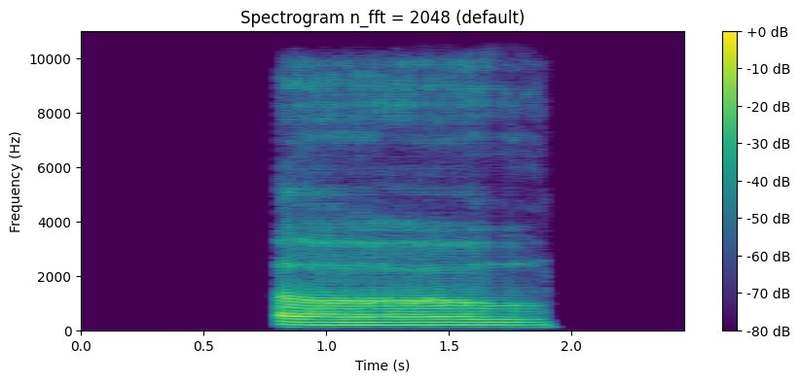

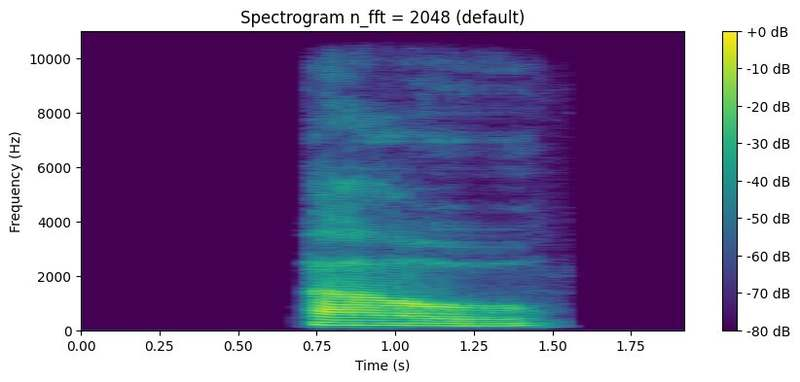

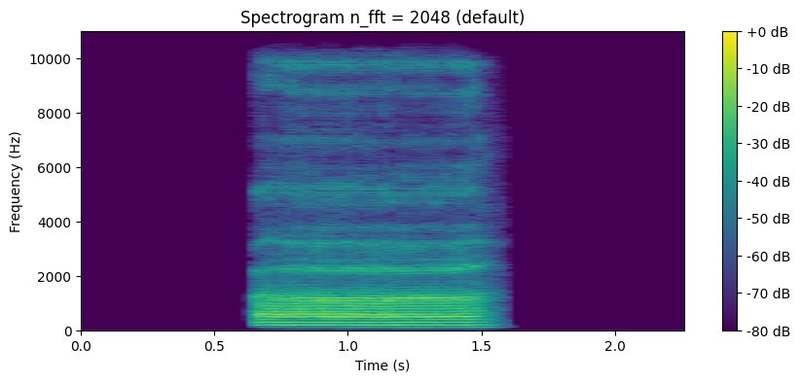

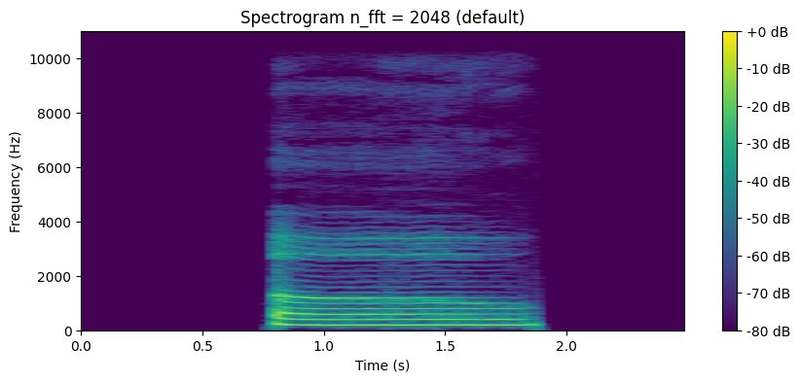

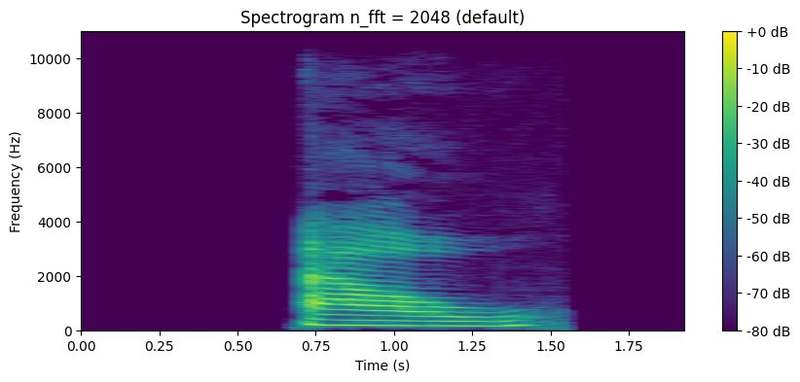

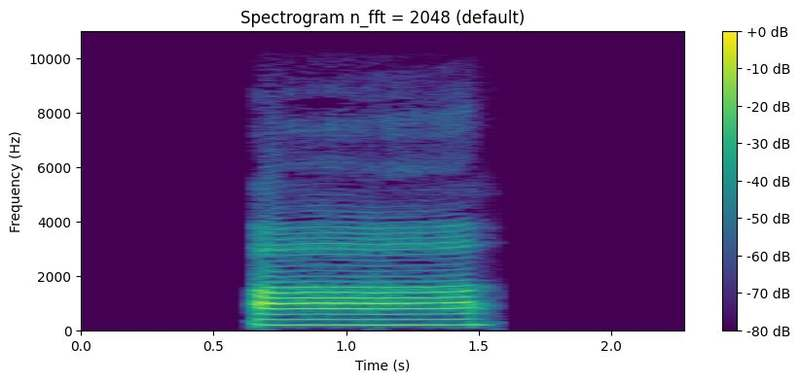

In [50]:
for time, sampling in zip(times, samplings):
    t_D = lb.stft(time, n_fft= 2048)
    S_db = lb.amplitude_to_db(np.abs(t_D), ref=np.max)

    plt.figure(figsize=(10, 4))
    plt.imshow(S_db, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(time) / sampling, 0, sampling / 2])
    plt.colorbar(format="%+2.0f dB")
    plt.title("Spectrogram n_fft = 2048 (default)")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.show()

#### n_fft = 2048(Narrowband) places focus on frequency resolution of the spectrogram, making harmonic width and formants to appear more clearly and easier to analyze.

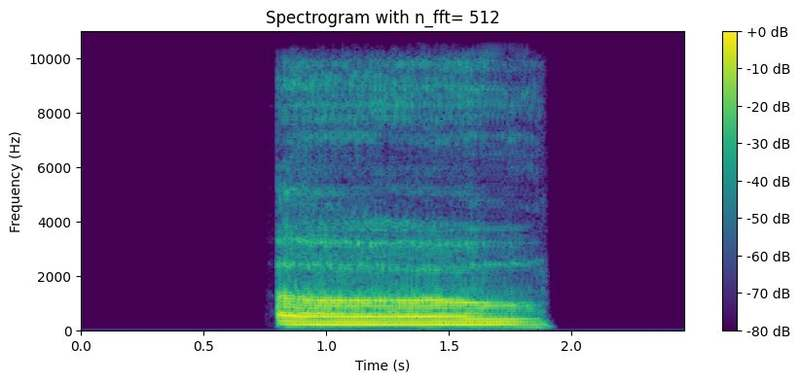

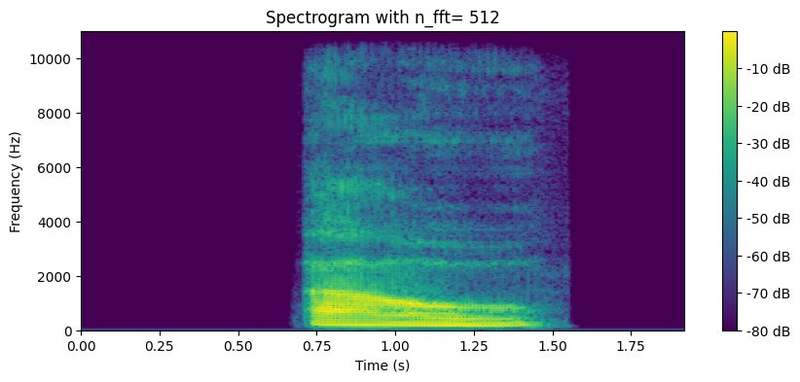

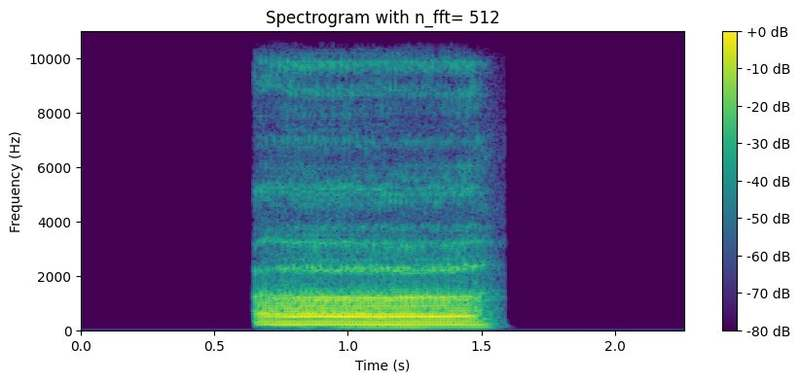

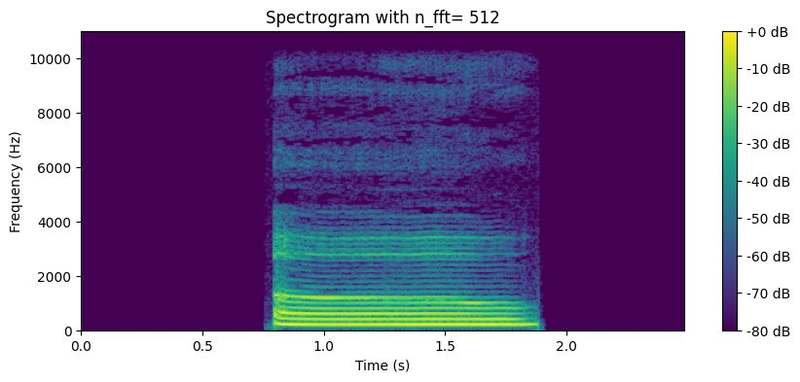

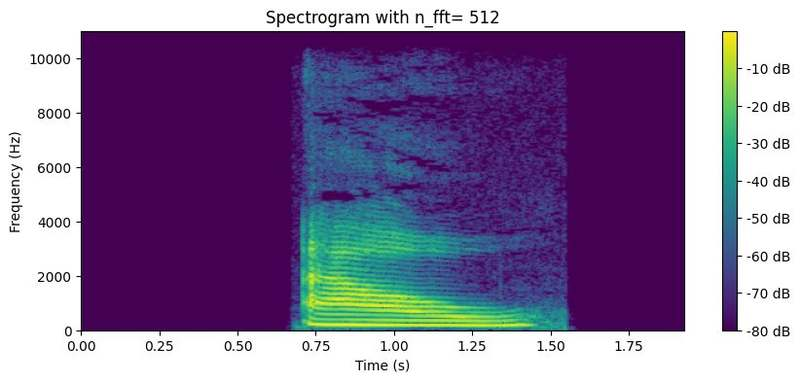

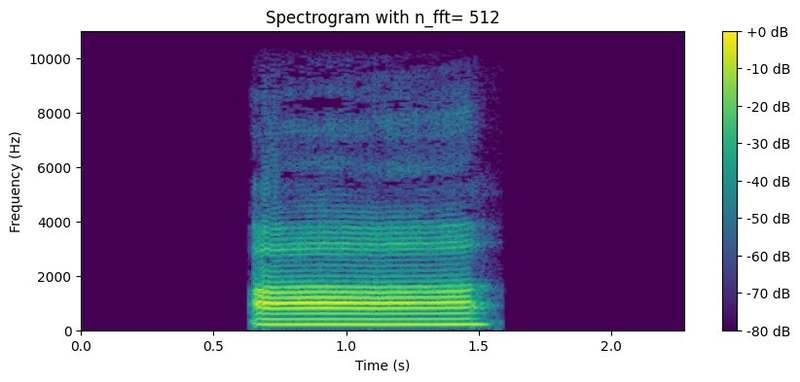

In [51]:
for time, sampling in zip(times, samplings):
    D = lb.stft(time, n_fft=512)
    S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)
    plt.figure(figsize=(10, 4))
    plt.imshow(S_db, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(time) / sampling, 0, sampling / 2])
    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Spectrogram with n_fft= 512")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.show()

### 512 n_fft (Wideband) places more focus on the time aspect of the spectrogram, showing the changes in amplitude and formants more clearly in exchange for making the harmonics harder to distinguish.

## 3 Gender-Based Analysis

### Male Voice

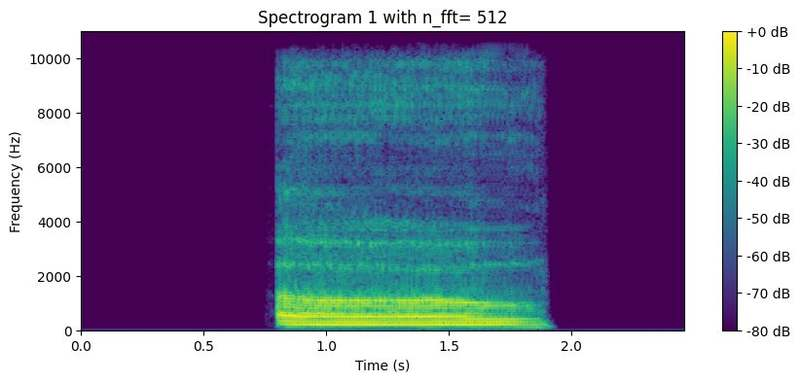

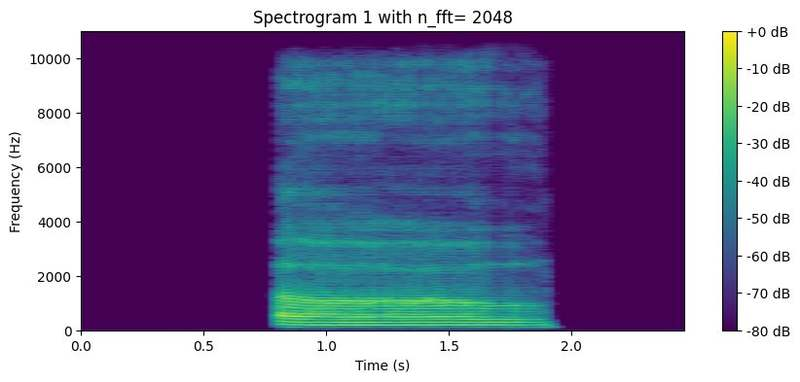

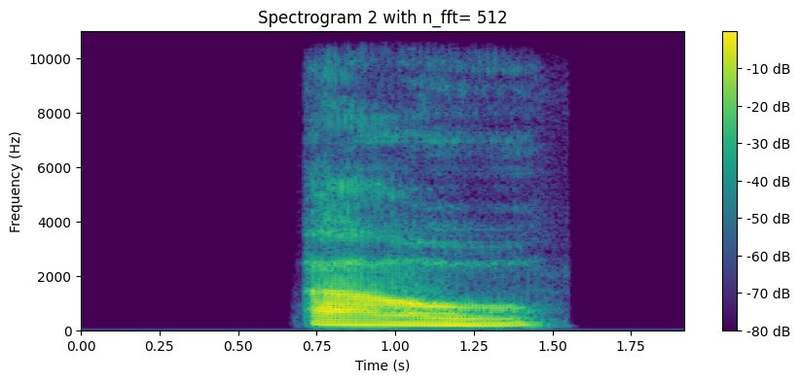

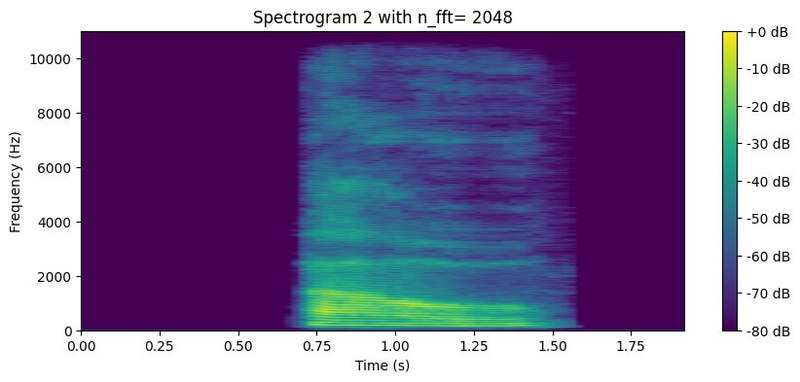

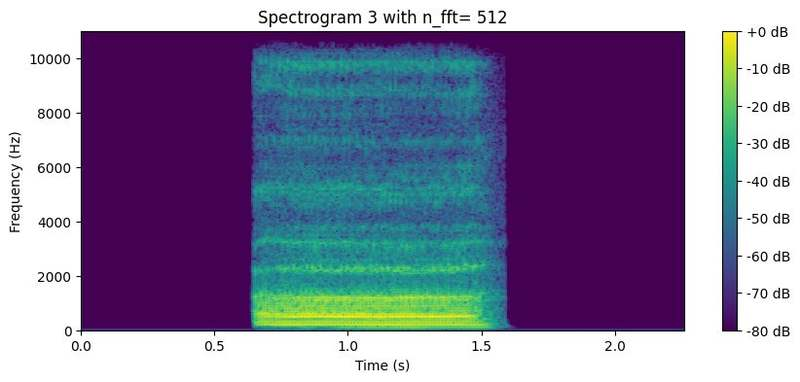

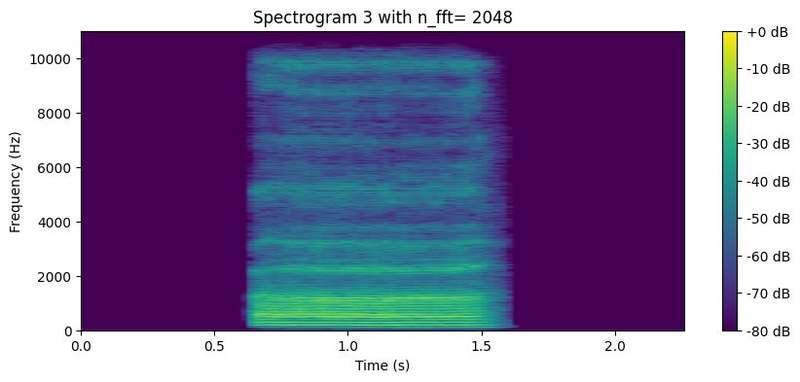

In [52]:
n_ffts= [512, 2048]
ids= [1,2,3]
for id, time, sampling in zip(ids, male_times, male_sampling):
    for n_fft in n_ffts: 
        D = lb.stft(time, n_fft=n_fft)
        S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)
        plt.figure(figsize=(10, 4))
        plt.imshow(S_db, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(time) / sampling, 0, sampling / 2])
        plt.colorbar(format="%+2.0f dB")
        plt.title(f"Spectrogram {id} with n_fft= {n_fft}")
        plt.xlabel("Time (s)")
        plt.ylabel("Frequency (Hz)")
        plt.show()

### Female Voice

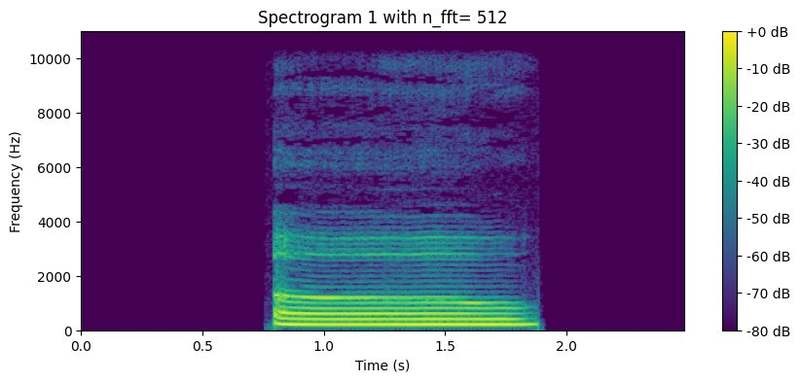

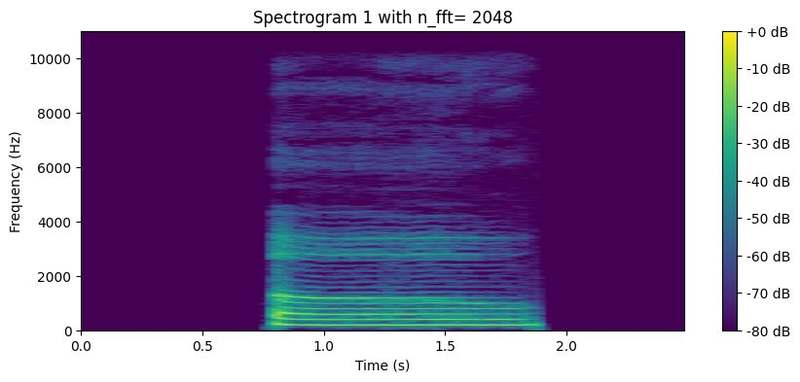

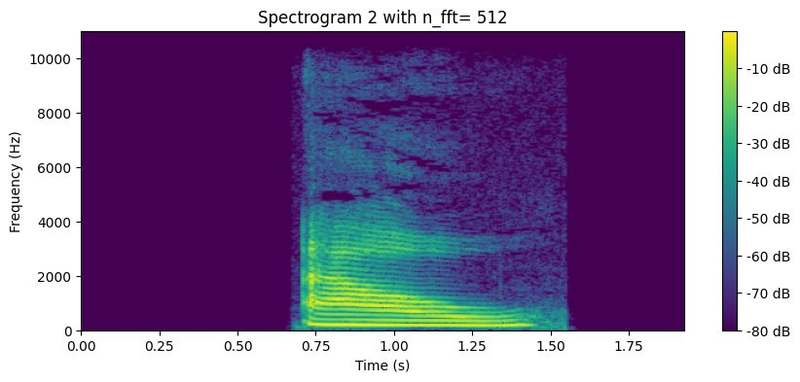

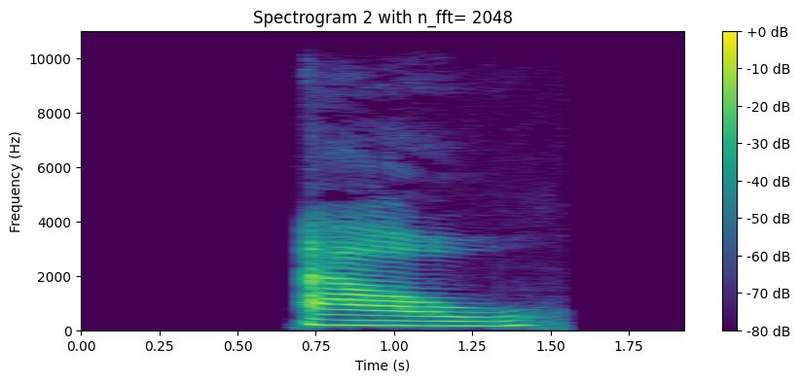

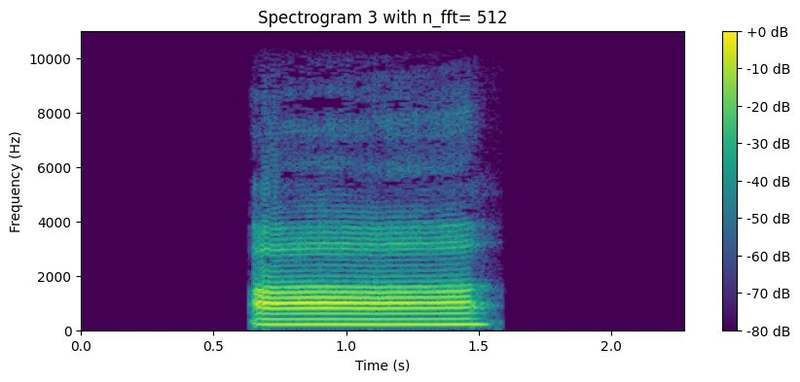

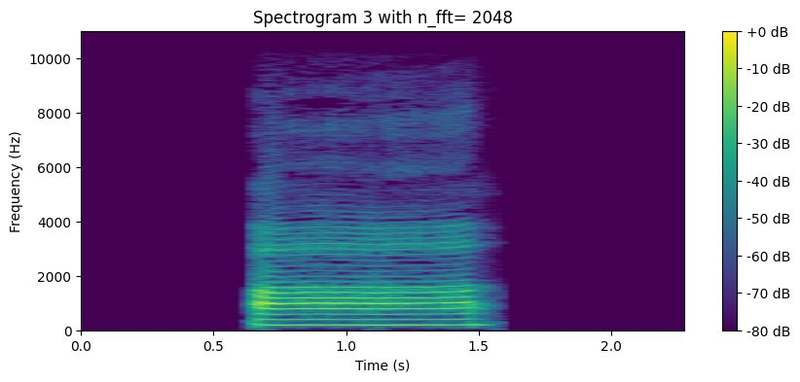

In [53]:
for id, time, sampling in zip(ids, female_times, female_sampling):
    for n_fft in n_ffts: 
        D = lb.stft(time, n_fft=n_fft)
        S_db = lb.amplitude_to_db(np.abs(D), ref=np.max)
        plt.figure(figsize=(10, 4))
        plt.imshow(S_db, aspect='auto', origin='lower', cmap='viridis', extent=[0, len(time) / sampling, 0, sampling / 2])
        plt.colorbar(format="%+2.0f dB")
        plt.title(f"Spectrogram {id} with n_fft= {n_fft}")
        plt.xlabel("Time (s)")
        plt.ylabel("Frequency (Hz)")
        plt.show()

## Gender Analysis:
### Looking at the wideband(512 n_fft) spectrograms, it can be seen that male voice exhibt stronger sound intensities at higher frequencies than female voices.
### On the other hand, it can be seen from the narrowband(2048 n_fft) spectrograms that female voices' formants (F1 and F2) are shifted towards higher frequencies.